# Negation, Contrast Words, and Punctuation Intensity

This notebook studies simple linguistic difficulty signals in the text classification dataset:
- negation words
- contrast words
- punctuation intensity

The objective is to identify whether some labels are associated with more complex or more emphatic language patterns.

## Interpretation of the linguistic-signal analysis

### 1. General overview

The dataset is perfectly balanced, with **252,000 documents** and exactly **50,400 examples per label**. This is important because it means that the differences observed across labels are not driven by class imbalance, but by real differences in language use.

The main findings from this analysis are:

- **Negation-like markers are strongly associated with lower labels**
- **Punctuation intensity is informative, but not monotonic**
- **Preprocessing helps lexical normalization, but removes most stylistic signals**
- The interpretation of negation must be made **carefully**, because lexical negation is not the same thing as negative sentiment

---

### 2. Negation is clearly correlated with lower labels

The percentage of documents containing at least one negation marker in the **preprocessed text** is:

- **Label 0:** 77.72%
- **Label 1:** 72.78%
- **Label 2:** 63.49%
- **Label 3:** 44.22%
- **Label 4:** 29.54%

This is a very strong and clean monotonic trend: the lower the label, the more likely the review is to contain a negation-like expression. This strongly suggests that negation is a meaningful linguistic signal for the task.

Typical examples likely include formulations such as:
- *doesn't work*
- *not as expected*
- *didn't receive the item*
- *nicht gut*
- *keine Funktion*

So at a high level, negation-like constructions are clearly more frequent in negative reviews.

---

### 3. However, the absolute percentages are high and should not be over-interpreted

Although the trend is meaningful, the absolute percentages are large, especially because even **label 4** still has almost **30%** of documents containing a negation marker.

This confirms something we already observed qualitatively in the examples:  
**the presence of a negation marker does not necessarily imply negative sentiment**.

Positive reviews may still contain negation in expressions such as:
- *No one ever complained...*
- *Do not hesitate to buy...*
- *Almost no room in my suitcase*
- *not bad*

Therefore, the negation feature should be interpreted as:

> **a noisy lexical proxy for negation-like constructions**, not as a direct measure of negative sentiment.

This distinction is important. The feature is still useful, but it is not semantically pure.

---

### 4. Top negation words: useful signal, but also likely noise

The most frequent negation markers are:

- `nicht` — 24.30%
- `not` — 17.31%
- `noch` — 5.51%
- `keine` — 4.47%
- `no` — 4.41%
- `don't` — 3.88%
- `didn't` — 2.95%
- `doesn't` — 2.70%
- `nichts` — 2.35%
- `kein` — 2.34%

Some of these are clearly meaningful and expected:
- `nicht`
- `not`
- `no`
- `don't`
- `didn't`
- `doesn't`
- `kein / keine`



### 5. Preprocessing and the contraction issue (`didn’t` → `didn t`)

A key point from debugging process is that **this analysis changed after we updated the preprocessing pipeline**.

Originally, the preprocessing pipeline used a token extraction rule that did **not preserve apostrophes inside words**. As a result, contractions such as:

- `didn't`
- `can't`
- `it's`

were split into forms like:

- `didn t`
- `can t`
- `it s`

This was a problem, because lexical negation detection could no longer correctly match words such as `didn't`. In other words, before the update, the preprocessing pipeline was **destroying part of the negation signal**.

We fixed this by:
1. **normalizing typographic apostrophes** (`didn’t` → `didn't`)
2. **changing the token regex so contractions remain single tokens**

This explains why the preprocessing-based negation results are now more reliable.  
It also explains why the percentage of documents with negation is slightly higher after preprocessing than in the raw text: the updated preprocessing makes lexical matching more consistent.

The difference is visible in the deltas:

- Label 0: +2.83 points
- Label 1: +2.76
- Label 2: +2.49
- Label 3: +1.95
- Label 4: +1.49

So preprocessing is not radically changing the negation pattern, but it is making it more robust and better aligned with the intended lexical rules.

---

### 6. Punctuation intensity is informative, but in a different way

The punctuation analysis gives a different type of signal.

#### Exclamation marks

Raw average exclamation marks by label:

- Label 0: **0.737**
- Label 4: **0.699**
- Label 3: **0.334**
- Label 1: **0.303**
- Label 2: **0.229**

This is not monotonic. Instead, both extremes — **very negative** and **very positive** reviews — use many exclamation marks.

This suggests that exclamation marks capture:

> **emotional intensity**, not sentiment direction.

That makes intuitive sense:
- negative users use exclamation marks to express frustration or anger
- positive users use them to express enthusiasm

So exclamation marks are useful, but they are more likely to be a signal of **expressiveness** than of negativity alone.

---

#### Question marks

Raw average question marks by label:

- Label 0: **0.084**
- Label 1: **0.057**
- Label 2: **0.048**
- Label 3: **0.024**
- Label 4: **0.013**

This signal is much more monotonic. Lower-rated reviews contain more question marks, which may reflect:
- confusion
- complaint-like writing
- problem reporting
- rhetorical frustration

So question marks seem more directly linked to dissatisfaction than exclamation marks.

---

#### Repeated punctuation and mixed punctuation runs

Repeated exclamation marks, repeated question marks, and mixed punctuation runs are all strongest in **label 0**.

This suggests that very negative reviews tend to use more expressive, emphatic, or frustrated punctuation patterns. These are potentially useful style features for the classification task.

---

#### Uppercase ratio

Uppercase usage is highest for:
- Label 4: **0.0478**
- Label 0: **0.0473**

Again, the pattern is strongest at the extremes, which suggests that uppercase is also more related to emphasis and emotional style than to sentiment direction alone.

This signal appears weaker than negation or punctuation repetition, but it may still be useful as a style feature.

---

### 7. Preprocessing removes almost all punctuation-based signal

A very important finding is that after preprocessing:

- exclamation marks go to **0**
- question marks go to **0**
- repeated punctuation goes to **0**
- uppercase ratio goes to **0**

This is expected from the current normalization pipeline, but it has a major implication:

> **the preprocessing pipeline removes almost all stylistic punctuation/case information**

This means that preprocessing has a mixed effect:
- it helps lexical normalization (especially for contractions and negation matching)
- but it destroys stylistic/emotional signals carried by punctuation and uppercase usage

This is one of the most practically important conclusions from the notebook.

---

### 8. Main takeaways to keep in mind

From this analysis, the following points should be retained:

#### (a) Negation is a strong signal, but not a direct sentiment label
Negation-like markers are much more frequent in low-rated reviews, so they are useful.  
However, they also appear in positive reviews, often in benign or even strongly positive constructions. So the feature should be treated as a **noisy lexical indicator**, not as a direct measure of negative sentiment.

#### (b) The lexicon should be refined
Some negation markers are clearly useful (`not`, `nicht`, `don't`, `didn't`, etc.), but some are likely too ambiguous (`noch`). The lexicon should be reviewed to reduce false positives.

#### (c) Updating preprocessing was necessary
Before the update, contractions such as `didn't` were being broken into `didn t`, which damaged negation detection. The updated preprocessing pipeline now preserves contractions, making lexical analysis more reliable.

#### (d) Punctuation carries useful signal that preprocessing currently removes
Raw punctuation features are clearly informative:
- exclamation marks reflect emotional intensity
- question marks and repeated punctuation are more concentrated in negative reviews
- uppercase usage also reflects emphasis

If the final modeling pipeline only uses fully normalized text, these signals may be lost.

#### (e) A future direction is to combine normalized lexical features and raw style features
The most promising setup may be to keep:
- lexical features on preprocessed text
- punctuation / uppercase / stylistic features on raw text

This would allow the model to benefit from both normalization and expressive signal.

---

### 9. Final conclusion

This analysis shows that linguistic markers of **negation** and **punctuation intensity** are both informative, but they capture different phenomena.

Negation is strongly associated with lower labels and appears to be a robust lexical signal, especially after fixing the preprocessing pipeline so that contractions like `didn't` are preserved. However, negation markers also appear in positive contexts, which means they should be interpreted carefully and not equated with negative sentiment.

Punctuation intensity, on the other hand, captures emotional style rather than sentiment direction. Both extremely negative and extremely positive reviews use more expressive punctuation, while question marks and repeated punctuation are more concentrated in negative reviews.

Finally, the notebook highlights a key preprocessing tradeoff: normalization improves lexical consistency, but removes much of the punctuation and case-based signal. This should be taken into account in any downstream modeling decisions.

In [1]:
import os
import re
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.max_rows", 100)

current_dir = Path.cwd()

if current_dir.name == "data_analysis":
    REPO_ROOT = current_dir.parent
else:
    REPO_ROOT = current_dir

DATA_DIR = REPO_ROOT / "data"
ANALYSIS_DIR = REPO_ROOT / "data_analysis"

if str(REPO_ROOT) not in sys.path:
    sys.path.append(str(REPO_ROOT))

if str(ANALYSIS_DIR) not in sys.path:
    sys.path.append(str(ANALYSIS_DIR))

print("REPO_ROOT:", REPO_ROOT)
print("DATA_DIR:", DATA_DIR)
print("ANALYSIS_DIR:", ANALYSIS_DIR)

REPO_ROOT: /Users/yousseftorgeman/Desktop/text_classifier
DATA_DIR: /Users/yousseftorgeman/Desktop/text_classifier/data
ANALYSIS_DIR: /Users/yousseftorgeman/Desktop/text_classifier/data_analysis


In [2]:
from data_analysis.utils.text_preprocessing import TextPreprocessor

## 1. Load data

In [3]:
train_path = DATA_DIR / "train.csv"
assert train_path.exists(), f"Missing file: {train_path}"

train_df = pd.read_csv(train_path)

TEXT_COL = "sentence"
LABEL_COL = "label"

assert TEXT_COL in train_df.columns, f"Column '{TEXT_COL}' not found"
assert LABEL_COL in train_df.columns, f"Column '{LABEL_COL}' not found"

train_df[TEXT_COL] = train_df[TEXT_COL].fillna("").astype(str).str.strip()

print(f"Train shape: {train_df.shape}")
display(train_df.head())

Train shape: (252000, 3)


,id,sentence,label
0,0,"Moderner Weihnachtsbaum in weiß\n\nDieses Jahr wollte ich keinen echten Baum und so hab ich mich für einen modernen kleinen in weiß entschieden. Als das Paket kam und ich den Baum ausgepackt hab, ...",4
1,1,"Passt wie angegossen\n\nTasche kam schnell und gut Verpackt an, die kleine DJI Ryze Tello passt perfekt rein sowie der Controller , zusätzlich sind noch 2 schlitze für Reserve Akkus und 3 Vertiefu...",4
2,2,Schlechte Qualität\n\nIch habe sehr lange auf diesen Käfig gespart. Leider muss ich mich den vorherigen Rezensionen anschließen. Die Qualität ist wirklich sehr schlecht. Überall ist das Holz gespl...,1
3,3,Bestellung nie angekommen\n\n-5 Sterne..... Am 15.5 bestellt und bis jetzt immer noch nicht da. Das Teil können Sie behalten,0
4,4,"Für mich gar nicht gut\n\nMacht das Makeup gar nicht haltbarer. Hinterlässt ein klebriges Gefühl auf der Haut, was gar nicht verschwindet. Sprühkopf verteilt das Produkt überhaupt nicht gut",1


## 2. Generate preprocessed text

In [4]:
PREPROCESSED_COL = "_preprocessed_text"

print("Generating preprocessed text with the project's preprocessing utility...")

preprocessor = TextPreprocessor()
train_df[PREPROCESSED_COL] = train_df[TEXT_COL].apply(preprocessor.preprocess)

display(train_df[[TEXT_COL, PREPROCESSED_COL, LABEL_COL]].head())

Generating preprocessed text with the project's preprocessing utility...


,sentence,_preprocessed_text,label
0,"Moderner Weihnachtsbaum in weiß\n\nDieses Jahr wollte ich keinen echten Baum und so hab ich mich für einen modernen kleinen in weiß entschieden. Als das Paket kam und ich den Baum ausgepackt hab, ...",moderner weihnachtsbaum in weiß dieses jahr wollte ich keinen echten baum und so hab ich mich für einen modernen kleinen in weiß entschieden als das paket kam und ich den baum ausgepackt hab dacht...,4
1,"Passt wie angegossen\n\nTasche kam schnell und gut Verpackt an, die kleine DJI Ryze Tello passt perfekt rein sowie der Controller , zusätzlich sind noch 2 schlitze für Reserve Akkus und 3 Vertiefu...",passt wie angegossen tasche kam schnell und gut verpackt an die kleine dji ryze tello passt perfekt rein sowie der controller zusätzlich sind noch 2 schlitze für reserve akkus und 3 vertiefungen f...,4
2,Schlechte Qualität\n\nIch habe sehr lange auf diesen Käfig gespart. Leider muss ich mich den vorherigen Rezensionen anschließen. Die Qualität ist wirklich sehr schlecht. Überall ist das Holz gespl...,schlechte qualität ich habe sehr lange auf diesen käfig gespart leider muss ich mich den vorherigen rezensionen anschließen die qualität ist wirklich sehr schlecht überall ist das holz gesplittert...,1
3,Bestellung nie angekommen\n\n-5 Sterne..... Am 15.5 bestellt und bis jetzt immer noch nicht da. Das Teil können Sie behalten,bestellung nie angekommen 5 sterne am 15 5 bestellt und bis jetzt immer noch nicht da das teil können sie behalten,0
4,"Für mich gar nicht gut\n\nMacht das Makeup gar nicht haltbarer. Hinterlässt ein klebriges Gefühl auf der Haut, was gar nicht verschwindet. Sprühkopf verteilt das Produkt überhaupt nicht gut",für mich gar nicht gut macht das makeup gar nicht haltbarer hinterlässt ein klebriges gefühl auf der haut was gar nicht verschwindet sprühkopf verteilt das produkt überhaupt nicht gut,1


In [5]:
def print_section(title: str):
    print("\n" + "=" * 100)
    print(title)
    print("=" * 100)

## 3. Define lexical patterns

In [38]:
NEGATION_WORDS_EN = [
    "not", "no", "never", "nothing", "none", "nobody", "nowhere", "neither", "nor",
    "can't", "don't", "won't", "isn't", "aren't", "wasn't", "weren't", "didn't",
    "doesn't", "haven't", "hasn't", "hadn't"
]

NEGATION_WORDS_DE = [
    "nicht", "kein", "keine", "keinen", "keinem", "keiner", "keines",
    "nie", "niemals", "nichts", "niemand", "nirgendwo", "weder", "noch",
    "kann nicht", "nicht können", "nicht ist", "nicht sind",
    "nicht war", "nicht waren", "nicht haben", "nicht hat", "nicht hatte"
]

CONTRAST_WORDS_EN = [
    "but", "however", "although", "though", "yet", "nevertheless", "nonetheless", "despite", "in contrast", "on the other hand", "whereas"
]

CONTRAST_WORDS_DE = [
    "aber", "jedoch", "obwohl", "dennoch", "trotzdem", "hingegen, im Gegensatz dazu, andererseits, während"
]

NEGATION_WORDS = sorted(set(NEGATION_WORDS_EN + NEGATION_WORDS_DE))
CONTRAST_WORDS = sorted(set(CONTRAST_WORDS_EN + CONTRAST_WORDS_DE))

print("Negation words:", NEGATION_WORDS)
print("Contrast words:", CONTRAST_WORDS)

Negation words: ["aren't", "can't", "didn't", "doesn't", "don't", "hadn't", "hasn't", "haven't", "isn't", 'kann nicht', 'kein', 'keine', 'keinem', 'keinen', 'keiner', 'keines', 'neither', 'never', 'nicht', 'nicht haben', 'nicht hat', 'nicht hatte', 'nicht ist', 'nicht können', 'nicht sind', 'nicht war', 'nicht waren', 'nichts', 'nie', 'niemals', 'niemand', 'nirgendwo', 'no', 'nobody', 'noch', 'none', 'nor', 'not', 'nothing', 'nowhere', "wasn't", 'weder', "weren't", "won't"]
Contrast words: ['aber', 'although', 'but', 'dennoch', 'despite', 'hingegen, im Gegensatz dazu, andererseits, während', 'however', 'in contrast', 'jedoch', 'nevertheless', 'nonetheless', 'obwohl', 'on the other hand', 'though', 'trotzdem', 'whereas', 'yet']


Negation words: ['ni', 'non']
Contrast words: ['aber', 'although', 'but', 'dennoch', 'despite', 'hingegen, im Gegensatz dazu, andererseits, während', 'however', 'in contrast', 'jedoch', 'nevertheless', 'nonetheless', 'obwohl', 'on the other hand', 'though', 'trotzdem', 'whereas', 'yet']


In [39]:
def contains_any_word(text: str, words: list[str]) -> int:
    text = str(text).lower()
    for word in words:
        pattern = rf"\b{re.escape(word)}\b"
        if re.search(pattern, text):
            return 1
    return 0

def count_word_occurrences(text: str, words: list[str]) -> int:
    text = str(text).lower()
    total = 0
    for word in words:
        pattern = rf"\b{re.escape(word)}\b"
        total += len(re.findall(pattern, text))
    return total

## 4. Negation analysis

In [40]:
train_df["has_negation_raw"] = train_df[TEXT_COL].apply(lambda x: contains_any_word(x, NEGATION_WORDS))
train_df["negation_count_raw"] = train_df[TEXT_COL].apply(lambda x: count_word_occurrences(x, NEGATION_WORDS))

train_df["has_negation_preprocessed"] = train_df[PREPROCESSED_COL].apply(lambda x: contains_any_word(x, NEGATION_WORDS))
train_df["negation_count_preprocessed"] = train_df[PREPROCESSED_COL].apply(lambda x: count_word_occurrences(x, NEGATION_WORDS))

display(
    train_df[
        [TEXT_COL, PREPROCESSED_COL, LABEL_COL, "has_negation_raw", "negation_count_raw"]
    ].head(10)
    , train_df[
        [TEXT_COL, PREPROCESSED_COL, LABEL_COL, "has_negation_preprocessed", "negation_count_preprocessed"]
    ].head(10)
)

,sentence,_preprocessed_text,label,has_negation_raw,negation_count_raw
0,"Moderner Weihnachtsbaum in weiß\n\nDieses Jahr wollte ich keinen echten Baum und so hab ich mich für einen modernen kleinen in weiß entschieden. Als das Paket kam und ich den Baum ausgepackt hab, ...",moderner weihnachtsbaum in weiß dieses jahr wollte ich keinen echten baum und so hab ich mich für einen modernen kleinen in weiß entschieden als das paket kam und ich den baum ausgepackt hab dacht...,4,1,2
1,"Passt wie angegossen\n\nTasche kam schnell und gut Verpackt an, die kleine DJI Ryze Tello passt perfekt rein sowie der Controller , zusätzlich sind noch 2 schlitze für Reserve Akkus und 3 Vertiefu...",passt wie angegossen tasche kam schnell und gut verpackt an die kleine dji ryze tello passt perfekt rein sowie der controller zusätzlich sind noch 2 schlitze für reserve akkus und 3 vertiefungen f...,4,1,1
2,Schlechte Qualität\n\nIch habe sehr lange auf diesen Käfig gespart. Leider muss ich mich den vorherigen Rezensionen anschließen. Die Qualität ist wirklich sehr schlecht. Überall ist das Holz gespl...,schlechte qualität ich habe sehr lange auf diesen käfig gespart leider muss ich mich den vorherigen rezensionen anschließen die qualität ist wirklich sehr schlecht überall ist das holz gesplittert...,1,0,0
3,Bestellung nie angekommen\n\n-5 Sterne..... Am 15.5 bestellt und bis jetzt immer noch nicht da. Das Teil können Sie behalten,bestellung nie angekommen 5 sterne am 15 5 bestellt und bis jetzt immer noch nicht da das teil können sie behalten,0,1,3
4,"Für mich gar nicht gut\n\nMacht das Makeup gar nicht haltbarer. Hinterlässt ein klebriges Gefühl auf der Haut, was gar nicht verschwindet. Sprühkopf verteilt das Produkt überhaupt nicht gut",für mich gar nicht gut macht das makeup gar nicht haltbarer hinterlässt ein klebriges gefühl auf der haut was gar nicht verschwindet sprühkopf verteilt das produkt überhaupt nicht gut,1,1,4
5,Jürgen Boos\n\nLäuft nicht auf allen meinen Geräten einwandfrei.,jürgen boos läuft nicht auf allen meinen geräten einwandfrei,2,1,1
6,"I hope they get it togather.\n\nThe design was good. The bad part it did not preform, I used an extra att. still not good on SW AIR bands. Will buy another brand.",i hope they get it togather the design was good the bad part it did not preform i used an extra att still not good on sw air bands will buy another brand,1,1,2
7,"Schön aber naja..\n\nSitzt ein bisschen weit und der Stoff ist sehr dünn. Farbe und Druck sind toll, bin gespannt wie es nach dem ersten Waschgang aussieht",schön aber naja sitzt ein bisschen weit und der stoff ist sehr dünn farbe und druck sind toll bin gespannt wie es nach dem ersten waschgang aussieht,2,0,0
8,Angenehm zu tragen.\n\nSehr praktisch. Leider keine Unterteilung fürs Handy. Das rutscht in der großen Tasche immer nach unten. Auch für den Schlüssel wäre eine kleine Tasche nicht schlecht.,angenehm zu tragen sehr praktisch leider keine unterteilung fürs handy das rutscht in der großen tasche immer nach unten auch für den schlüssel wäre eine kleine tasche nicht schlecht,3,1,2
9,"Eh - for me, anyway\n\nFeel was ok-ish, didn’t care for the color. Hard to tell online, it’s lighter than I wanted. They did hold up to a potential Velcro snag. Might be perfect for someone with f...",eh for me anyway feel was ok ish didn't care for the color hard to tell online it's lighter than i wanted they did hold up to a potential velcro snag might be perfect for someone with fair skin,1,0,0


,sentence,_preprocessed_text,label,has_negation_preprocessed,negation_count_preprocessed
0,"Moderner Weihnachtsbaum in weiß\n\nDieses Jahr wollte ich keinen echten Baum und so hab ich mich für einen modernen kleinen in weiß entschieden. Als das Paket kam und ich den Baum ausgepackt hab, ...",moderner weihnachtsbaum in weiß dieses jahr wollte ich keinen echten baum und so hab ich mich für einen modernen kleinen in weiß entschieden als das paket kam und ich den baum ausgepackt hab dacht...,4,1,2
1,"Passt wie angegossen\n\nTasche kam schnell und gut Verpackt an, die kleine DJI Ryze Tello passt perfekt rein sowie der Controller , zusätzlich sind noch 2 schlitze für Reserve Akkus und 3 Vertiefu...",passt wie angegossen tasche kam schnell und gut verpackt an die kleine dji ryze tello passt perfekt rein sowie der controller zusätzlich sind noch 2 schlitze für reserve akkus und 3 vertiefungen f...,4,1,1
2,Schlechte Qualität\n\nIch habe sehr lange auf diesen Käfig gespart. Leider muss ich mich den vorherigen Rezensionen anschließen. Die Qualität ist wirklich sehr schlecht. Überall ist das Holz gespl...,schlechte qualität ich habe sehr lange auf diesen käfig gespart leider muss ich mich den vorherigen rezensionen anschließen die qualität ist wirklich sehr schlecht überall ist das holz gesplittert...,1,0,0
3,Bestellung nie angekommen\n\n-5 Sterne..... Am 15.5 bestellt und bis jetzt immer noch nicht da. Das Teil können Sie behalten,bestellung nie angekommen 5 sterne am 15 5 bestellt und bis jetzt immer noch nicht da das teil können sie behalten,0,1,3
4,"Für mich gar nicht gut\n\nMacht das Makeup gar nicht haltbarer. Hinterlässt ein klebriges Gefühl auf der Haut, was gar nicht verschwindet. Sprühkopf verteilt das Produkt überhaupt nicht gut",für mich gar nicht gut macht das makeup gar nicht haltbarer hinterlässt ein klebriges gefühl auf der haut was gar nicht verschwindet sprühkopf verteilt das produkt überhaupt nicht gut,1,1,4
5,Jürgen Boos\n\nLäuft nicht auf allen meinen Geräten einwandfrei.,jürgen boos läuft nicht auf allen meinen geräten einwandfrei,2,1,1
6,"I hope they get it togather.\n\nThe design was good. The bad part it did not preform, I used an extra att. still not good on SW AIR bands. Will buy another brand.",i hope they get it togather the design was good the bad part it did not preform i used an extra att still not good on sw air bands will buy another brand,1,1,2
7,"Schön aber naja..\n\nSitzt ein bisschen weit und der Stoff ist sehr dünn. Farbe und Druck sind toll, bin gespannt wie es nach dem ersten Waschgang aussieht",schön aber naja sitzt ein bisschen weit und der stoff ist sehr dünn farbe und druck sind toll bin gespannt wie es nach dem ersten waschgang aussieht,2,0,0
8,Angenehm zu tragen.\n\nSehr praktisch. Leider keine Unterteilung fürs Handy. Das rutscht in der großen Tasche immer nach unten. Auch für den Schlüssel wäre eine kleine Tasche nicht schlecht.,angenehm zu tragen sehr praktisch leider keine unterteilung fürs handy das rutscht in der großen tasche immer nach unten auch für den schlüssel wäre eine kleine tasche nicht schlecht,3,1,2
9,"Eh - for me, anyway\n\nFeel was ok-ish, didn’t care for the color. Hard to tell online, it’s lighter than I wanted. They did hold up to a potential Velcro snag. Might be perfect for someone with f...",eh for me anyway feel was ok ish didn't care for the color hard to tell online it's lighter than i wanted they did hold up to a potential velcro snag might be perfect for someone with fair skin,1,1,1


In [41]:
preprocessor = TextPreprocessor()
print(preprocessor.preprocess("Feel was ok-ish, didn’t care for the color."))

feel was ok ish didn't care for the color


In [42]:
print_section("4.1 Negation summary by label")

negation_summary = (
    train_df.groupby(LABEL_COL)
    .agg(
        n_docs=(TEXT_COL, "size"),

        docs_with_negation_raw=("has_negation_raw", "sum"),
        avg_negation_count_raw=("negation_count_raw", "mean"),

        docs_with_negation_preprocessed=("has_negation_preprocessed", "sum"),
        avg_negation_count_preprocessed=("negation_count_preprocessed", "mean"),
    )
    .reset_index()
)

negation_summary["pct_docs_with_negation_raw"] = (
    100 * negation_summary["docs_with_negation_raw"] / negation_summary["n_docs"]
)

negation_summary["pct_docs_with_negation_preprocessed"] = (
    100 * negation_summary["docs_with_negation_preprocessed"] / negation_summary["n_docs"]
)

negation_summary = negation_summary.sort_values(
    "pct_docs_with_negation_preprocessed", ascending=False
)

display(negation_summary)


4.1 Negation summary by label


,label,n_docs,docs_with_negation_raw,avg_negation_count_raw,docs_with_negation_preprocessed,avg_negation_count_preprocessed,pct_docs_with_negation_raw,pct_docs_with_negation_preprocessed
0,0,50400,37745,1.570278,39170,1.658472,74.890873,77.718254
1,1,50400,35288,1.405516,36680,1.484266,70.015873,72.777778
2,2,50400,30747,1.133175,32000,1.197262,61.005952,63.492063
3,3,50400,21303,0.705437,22288,0.745615,42.267857,44.222222
4,4,50400,14138,0.422242,14887,0.446845,28.051587,29.537698


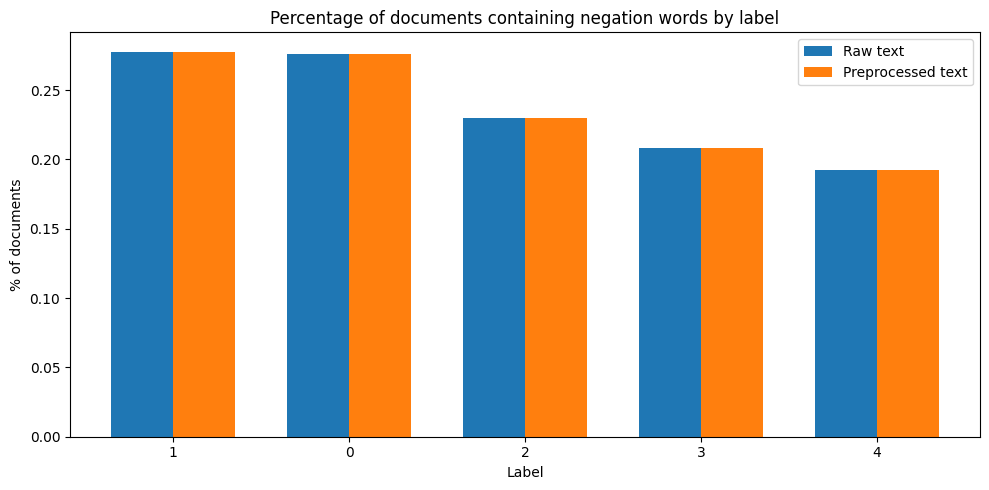

In [37]:
x = np.arange(len(negation_summary))
width = 0.35

plt.figure(figsize=(10, 5))
plt.bar(
    x - width/2,
    negation_summary["pct_docs_with_negation_raw"],
    width=width,
    label="Raw text"
)
plt.bar(
    x + width/2,
    negation_summary["pct_docs_with_negation_preprocessed"],
    width=width,
    label="Preprocessed text"
)

plt.xticks(x, negation_summary[LABEL_COL].astype(str))
plt.title("Percentage of documents containing negation words by label")
plt.xlabel("Label")
plt.ylabel("% of documents")
plt.legend()
plt.tight_layout()
plt.show()

In [43]:
from collections import Counter
import re

preprocessor = TextPreprocessor()

def matched_negation_words(text: str, words: list[str]):
    text_norm = preprocessor.normalize_for_lexical_matching(text)
    matched = []
    for word in words:
        word_norm = preprocessor.normalize_for_lexical_matching(word)
        pattern = rf"\b{re.escape(word_norm)}\b"
        if re.search(pattern, text_norm):
            matched.append(word_norm)
    return matched

doc_counter = Counter()
occ_counter = Counter()

for text in train_df[PREPROCESSED_COL]:
    matched = matched_negation_words(text, NEGATION_WORDS)
    
    # how many documents contain the word at least once
    for w in set(matched):
        doc_counter[w] += 1
    
    # total number of matched occurrences at document level
    for w in matched:
        occ_counter[w] += 1

n_docs = len(train_df)

neg_word_stats = pd.DataFrame({
    "negation_word": sorted(set(doc_counter.keys()) | set(occ_counter.keys()))
})

neg_word_stats["doc_count"] = neg_word_stats["negation_word"].map(doc_counter).fillna(0).astype(int)
neg_word_stats["occ_count"] = neg_word_stats["negation_word"].map(occ_counter).fillna(0).astype(int)
neg_word_stats["doc_pct"] = 100 * neg_word_stats["doc_count"] / n_docs
neg_word_stats["occ_per_doc_pct"] = 100 * neg_word_stats["occ_count"] / n_docs

neg_word_stats = neg_word_stats.sort_values("doc_pct", ascending=False)

display(neg_word_stats.head(30))

,negation_word,doc_count,occ_count,doc_pct,occ_per_doc_pct
18,nicht,61242,61242,24.302381,24.302381
37,not,43620,43620,17.309524,17.309524
34,noch,13873,13873,5.505159,5.505159
11,keine,11275,11275,4.474206,4.474206
32,no,11123,11123,4.413889,4.413889
4,don't,9773,9773,3.878175,3.878175
2,didn't,7424,7424,2.946032,2.946032
3,doesn't,6806,6806,2.700794,2.700794
27,nichts,5931,5931,2.353571,2.353571
10,kein,5889,5889,2.336905,2.336905


In [44]:
top_2_words = neg_word_stats.head(2)["negation_word"].tolist()
print("Top 2 negation words:", top_2_words)

for word in top_2_words:
    pattern = rf"\b{re.escape(word)}\b"
    
    examples = train_df[
        train_df[PREPROCESSED_COL].apply(
            lambda x: re.search(pattern, preprocessor.normalize_for_lexical_matching(x)) is not None
        )
    ][[TEXT_COL, PREPROCESSED_COL, LABEL_COL]].copy()

    print("\n" + "=" * 120)
    print(f"Examples for negation word: {word!r}")
    print("=" * 120)
    
    display(examples.head(10))

Top 2 negation words: ['nicht', 'not']

Examples for negation word: 'nicht'


,sentence,_preprocessed_text,label
3,Bestellung nie angekommen\n\n-5 Sterne..... Am 15.5 bestellt und bis jetzt immer noch nicht da. Das Teil können Sie behalten,bestellung nie angekommen 5 sterne am 15 5 bestellt und bis jetzt immer noch nicht da das teil können sie behalten,0
4,"Für mich gar nicht gut\n\nMacht das Makeup gar nicht haltbarer. Hinterlässt ein klebriges Gefühl auf der Haut, was gar nicht verschwindet. Sprühkopf verteilt das Produkt überhaupt nicht gut",für mich gar nicht gut macht das makeup gar nicht haltbarer hinterlässt ein klebriges gefühl auf der haut was gar nicht verschwindet sprühkopf verteilt das produkt überhaupt nicht gut,1
5,Jürgen Boos\n\nLäuft nicht auf allen meinen Geräten einwandfrei.,jürgen boos läuft nicht auf allen meinen geräten einwandfrei,2
8,Angenehm zu tragen.\n\nSehr praktisch. Leider keine Unterteilung fürs Handy. Das rutscht in der großen Tasche immer nach unten. Auch für den Schlüssel wäre eine kleine Tasche nicht schlecht.,angenehm zu tragen sehr praktisch leider keine unterteilung fürs handy das rutscht in der großen tasche immer nach unten auch für den schlüssel wäre eine kleine tasche nicht schlecht,3
19,"Installation für Laien sehr umständlich, trotzdem sehr gerne HP\n\nIch habe mich bewußt für HP entscheiden, denn ich habe bisher mit allen Geräten gute Erfahrungen gemacht. Die Installatation hat ...",installation für laien sehr umständlich trotzdem sehr gerne hp ich habe mich bewußt für hp entscheiden denn ich habe bisher mit allen geräten gute erfahrungen gemacht die installatation hat ewig g...,3
20,Artikel nicht erhalten!!!\n\nIch habe den Artikel nicht erhalten!!!! Ich möchte das Geld wieder zurück. Herzlichen Dank Sigrid,artikel nicht erhalten ich habe den artikel nicht erhalten ich möchte das geld wieder zurück herzlichen dank sigrid,0
21,"Habe meine Bestellung noch nicht erhalten\n\nWarte seit 19.06 auf meine Bestellung,ich hoffe das die noch dieses Jahr eintrifft.",habe meine bestellung noch nicht erhalten warte seit 19 06 auf meine bestellung ich hoffe das die noch dieses jahr eintrifft,0
25,Leider gibt es keine minus Sterne.\n\nKann ich nicht weiter empfehlen. Sind nie angekommen.,leider gibt es keine minus sterne kann ich nicht weiter empfehlen sind nie angekommen,0
42,Leider nicht so wie erwartet\n\nDas Fassungsvermögen beträgt max. 350 g. Ein Deckel ist schon beim erstenmal einfrieren kaputt gegangen. Die Deckel könnten fester auf den Dosen sitzen da bei breii...,leider nicht so wie erwartet das fassungsvermögen beträgt max 350 g ein deckel ist schon beim erstenmal einfrieren kaputt gegangen die deckel könnten fester auf den dosen sitzen da bei breiigen in...,2
51,"turban hält auf dem kopf sehr gut, saugfähigkeit nicht anders als bei einem herrkömmlichen handtuch\n\nnaaaja.... einen wirklich guten stern gibt es für den super tollen halt, der turban verrutsch...",turban hält auf dem kopf sehr gut saugfähigkeit nicht anders als bei einem herrkömmlichen handtuch naaaja einen wirklich guten stern gibt es für den super tollen halt der turban verrutscht durch d...,1



Examples for negation word: 'not'


,sentence,_preprocessed_text,label
6,"I hope they get it togather.\n\nThe design was good. The bad part it did not preform, I used an extra att. still not good on SW AIR bands. Will buy another brand.",i hope they get it togather the design was good the bad part it did not preform i used an extra att still not good on sw air bands will buy another brand,1
10,"Need modification for non-fat-faced amongst us\n\nFor a facemask, these are pretty good. I mean - let's face it.....it's not going to be the most comfortable thing. The one big problem I have with...",need modification for non fat faced amongst us for a facemask these are pretty good i mean let's face it it's not going to be the most comfortable thing the one big problem i have with these masks...,3
12,"Very well done, playing around with the standard tropes enough to be interesting but not enough to kill the heart\n\nI had somehow missed this movie’s existence, although that may be no big surpri...",very well done playing around with the standard tropes enough to be interesting but not enough to kill the heart i had somehow missed this movie's existence although that may be no big surprise si...,3
15,"Better out there but not horrible.\n\nUnfortunately this skirt wasn’t much of a help for my daughters dress. Also, the middle wire poked out a lot after a couple hours of wearing so it’s only good...",better out there but not horrible unfortunately this skirt wasn't much of a help for my daughters dress also the middle wire poked out a lot after a couple hours of wearing so it's only good for a...,1
16,"Don't buy these, it's not worth the few dollars.\n\nI wish I could give this a good review. These do not charge the iPhone. There are no 'accessory error' warnings etc. It simply does not work. If...",don't buy these it's not worth the few dollars i wish i could give this a good review these do not charge the iphone there are no accessory error warnings etc it simply does not work if i wanted t...,0
17,"A nice cream- not great\n\nIts a nice cream, but didnt realy help the neck as i excepted. Good smell",a nice cream not great its a nice cream but didnt realy help the neck as i excepted good smell,2
26,"Good but some are broken.\n\nI love coloring with these pens. However, a few of them are missing the rollerball tip so the ink just pours onto the paper. They were pretty inexpensive so not really...",good but some are broken i love coloring with these pens however a few of them are missing the rollerball tip so the ink just pours onto the paper they were pretty inexpensive so not really worth ...,2
28,"Not a perfect fit for a Ford Ranger, but it works!\n\nI installed this as a courtesy dome light in my 2002 Ford Ranger XLT. The length was spot on perfect, but the girth of the cylindrical metal c...",not a perfect fit for a ford ranger but it works i installed this as a courtesy dome light in my 2002 ford ranger xlt the length was spot on perfect but the girth of the cylindrical metal connecto...,3
31,"Good quality, but color not right for me\n\nSoft yarn, but the color was too green for me.",good quality but color not right for me soft yarn but the color was too green for me,3
35,"Poor Seam Work\n\nNice dress. Decent quality fabric, to where the light blue color didn't show too much of my undergarments. However, know that bra lines will show if the dress hugs you at all. St...",poor seam work nice dress decent quality fabric to where the light blue color didn't show too much of my undergarments however know that bra lines will show if the dress hugs you at all still it's...,2


In [46]:
top_2_words = neg_word_stats.head(2)["negation_word"].tolist()
print("Top 2 negation words:", top_2_words)

for word in top_2_words:
    pattern = rf"\b{re.escape(word)}\b"
    
    examples = train_df[
        (train_df[LABEL_COL] == 4) &
        train_df[PREPROCESSED_COL].apply(
            lambda x: re.search(pattern, preprocessor.normalize_for_lexical_matching(x)) is not None
        )
    ][[TEXT_COL, PREPROCESSED_COL, LABEL_COL]].copy()

    print("\n" + "=" * 120)
    print(f"Examples for negation word: {word!r} with label = 4")
    print(f"Number of matching documents: {len(examples)}")
    print("=" * 120)
    
    display(examples.head(10))

Top 2 negation words: ['nicht', 'not']

Examples for negation word: 'nicht' with label = 4
Number of matching documents: 4774


,sentence,_preprocessed_text,label
68,"macht genau was es soll und das gut\n\nich habe noch einen älteren Ebookreader ohne Hintergrundbeleuchtung und da der noch gut seinen Dienst verrichtet wollte ich nicht gleich einen neuen kaufen, ...",macht genau was es soll und das gut ich habe noch einen älteren ebookreader ohne hintergrundbeleuchtung und da der noch gut seinen dienst verrichtet wollte ich nicht gleich einen neuen kaufen sond...,4
113,"Schöne Gläser\n\nWir haben die Gläser bestellt, weil wir aus der Pfalz stammen und sie einfach gut finden. Sie sind im täglichen Gebrauch und dienen nicht nur für eine Weinschorle.",schöne gläser wir haben die gläser bestellt weil wir aus der pfalz stammen und sie einfach gut finden sie sind im täglichen gebrauch und dienen nicht nur für eine weinschorle,4
116,Ich weiß nicht\n\nIch weiß nicht weil ich warte für diese Produkte,ich weiß nicht ich weiß nicht weil ich warte für diese produkte,4
154,"Picknickdecke\n\nSuper Qualität, absolut praktisch, Wasser und Schmutz abweisend. Heute direkt im Garten ausprobiert 😁 einfach klasse. Dafür mal ein Daumen hoch endlich mal eine picknickdecke wo n...",picknickdecke super qualität absolut praktisch wasser und schmutz abweisend heute direkt im garten ausprobiert einfach klasse dafür mal ein daumen hoch endlich mal eine picknickdecke wo nicht jede...,4
215,Traumhafte Bildsprache mit Suchtfaktor\n\nDie Bilder und der Sprachstil sind traumhaft. Der Umgang von Tanja mit ihren Tieren und die Anmutung sind zum Dahinschmelzen. Leider habe ich sie noch nic...,traumhafte bildsprache mit suchtfaktor die bilder und der sprachstil sind traumhaft der umgang von tanja mit ihren tieren und die anmutung sind zum dahinschmelzen leider habe ich sie noch nicht li...,4
259,"Super cool\n\nmacht die Haare auf natürliche Weise schön blond; nicht zulange einwirken lassen, dann wird das Haar gelb; 3 Minuten reicht aus bei mittelblondem Haar;",super cool macht die haare auf natürliche weise schön blond nicht zulange einwirken lassen dann wird das haar gelb 3 minuten reicht aus bei mittelblondem haar,4
303,"Als Schießbrille gekauft und für gut befunden\n\nIch nutze diese Brille am Schießstand und habe bereits weitere Käufer werben können. Sie ist leicht, hat eine weiche Passform und stört auch unter ...",als schießbrille gekauft und für gut befunden ich nutze diese brille am schießstand und habe bereits weitere käufer werben können sie ist leicht hat eine weiche passform und stört auch unter dem g...,4
322,"Tolle Tasche in die alles rein passt\n\nVorne weg: Über die Haltbarkeit kann ich leider noch nicht urteilen. Aber ich kann sagen das in der Tasche endlich mal alles rein passt, was ich brauche, Ha...",tolle tasche in die alles rein passt vorne weg über die haltbarkeit kann ich leider noch nicht urteilen aber ich kann sagen das in der tasche endlich mal alles rein passt was ich brauche handy gel...,4
325,Toll\n\nTolles Preis-Leistungsverhältnis! Dieser Nasenhaarschneider ist der Hammer! Für diesen Preis habe ich weder bei Philips noch Braun oder Carrera etwas taugliches gefunden. Selbst für den do...,toll tolles preis leistungsverhältnis dieser nasenhaarschneider ist der hammer für diesen preis habe ich weder bei philips noch braun oder carrera etwas taugliches gefunden selbst für den doppelte...,4
375,"Tolles Gewürzregal\n\nIch habe wegen dem Preis lange überlegt ob ich das Regal kaufe, ich bereue es nicht! Es ist gut verarbeitet und sieht super schön aus in der Küche.",tolles gewürzregal ich habe wegen dem preis lange überlegt ob ich das regal kaufe ich bereue es nicht es ist gut verarbeitet und sieht super schön aus in der küche,4



Examples for negation word: 'not' with label = 4
Number of matching documents: 2863


,sentence,_preprocessed_text,label
40,Great Buy\n\nPerfect and exactly what I had been looking for. The Bluetooth for phone calls is perfect. No one ever complained about not hearing me clearly. I highly recommend,great buy perfect and exactly what i had been looking for the bluetooth for phone calls is perfect no one ever complained about not hearing me clearly i highly recommend,4
85,"Must buy!\n\nYes, I cleaned my phone surface correctly HANDS DOWN THE BEST SCREEN GUARD FOR YOUR PHONE Do not hesitate to buy this product, it is the best screen protector out in the market I have...",must buy yes i cleaned my phone surface correctly hands down the best screen guard for your phone do not hesitate to buy this product it is the best screen protector out in the market i have never...,4
205,"Nice an compact, fits anywhere\n\nThis is really nice since I have to travel often on the job. Hotels are consistently dry and this humidifier takes up ALMOST NO ROOM in my suitcase. It comes with...",nice an compact fits anywhere this is really nice since i have to travel often on the job hotels are consistently dry and this humidifier takes up almost no room in my suitcase it comes with sever...,4
236,"Very good\n\nWas very interesting & easy to follow . James Patterson very good author when he writes by himself, not so good when he has a co-author.",very good was very interesting easy to follow james patterson very good author when he writes by himself not so good when he has a co author,4
398,Great. Super Easy To Install!\n\nThis works great. The fog light switch was coming on by itself and it was time for a replacement. I'm not an auto mechanic by any means so I was hesitant to do a D...,great super easy to install this works great the fog light switch was coming on by itself and it was time for a replacement i'm not an auto mechanic by any means so i was hesitant to do a diy on m...,4
418,"Simple, elegant solution to an annoying problem\n\nFirst of all, the magnetic installation is a brilliant design. It was amazingly easy to install and I was actually really impressed at how perfec...",simple elegant solution to an annoying problem first of all the magnetic installation is a brilliant design it was amazingly easy to install and i was actually really impressed at how perfectly al...,4
467,"Definatly for Word Search lovers.\n\nSo, I am a word search fiend. LOVE THEM. I was blown away when I stumbled upon this on Amazon. It seemed too good to be true! So, of course I immediately order...",definatly for word search lovers so i am a word search fiend love them i was blown away when i stumbled upon this on amazon it seemed too good to be true so of course i immediately ordered it i go...,4
709,"Game changing - would be perfect if strap were longer\n\nI rarely write reviews but this bag is game changing. Purses hurt my back and shoulders and even when I have pockets, trying to carry every...",game changing would be perfect if strap were longer i rarely write reviews but this bag is game changing purses hurt my back and shoulders and even when i have pockets trying to carry everything t...,4
824,Great price and should last my pregnancy\n\nI am currently 25 weeks pregnant and do weekly swim classes with my toddler. Just needed a suit that would fit to get me through the pregnancy. For some...,great price and should last my pregnancy i am currently 25 weeks pregnant and do weekly swim classes with my toddler just needed a suit that would fit to get me through the pregnancy for some reas...,4
1155,Great curtain\n\nI was looking for a clear curtain so I could see my kid in the bath but not get splashed on! This is perfect.,great curtain i was looking for a clear curtain so i could see my kid in the bath but not get splashed on this is perfect,4


## 6. Punctuation intensity analysis

In [47]:
def punctuation_features(text: str) -> pd.Series:
    text = str(text)
    return pd.Series({
        "n_exclamation": text.count("!"),
        "n_question": text.count("?"),
        "n_dots": text.count("."),
        "n_commas": text.count(","),
        "n_repeated_exclamation": len(re.findall(r"!{2,}", text)),
        "n_repeated_question": len(re.findall(r"\?{2,}", text)),
        "n_mixed_punct_runs": len(re.findall(r"[!?]{2,}", text)),
        "n_total_chars": len(text),
        "n_uppercase_chars": sum(1 for c in text if c.isupper()),
    })

punct_df = train_df[TEXT_COL].apply(punctuation_features)
train_df = pd.concat([train_df, punct_df], axis=1)

train_df["uppercase_ratio"] = np.where(
    train_df["n_total_chars"] > 0,
    train_df["n_uppercase_chars"] / train_df["n_total_chars"],
    0.0,
)

display(
    train_df[
        [
            TEXT_COL,
            LABEL_COL,
            "n_exclamation",
            "n_question",
            "n_repeated_exclamation",
            "n_repeated_question",
            "n_mixed_punct_runs",
            "uppercase_ratio",
        ]
    ].head(10)
)

,sentence,label,n_exclamation,n_question,n_repeated_exclamation,n_repeated_question,n_mixed_punct_runs,uppercase_ratio
0,"Moderner Weihnachtsbaum in weiß\n\nDieses Jahr wollte ich keinen echten Baum und so hab ich mich für einen modernen kleinen in weiß entschieden. Als das Paket kam und ich den Baum ausgepackt hab, ...",4,0,0,0,0,0,0.036101
1,"Passt wie angegossen\n\nTasche kam schnell und gut Verpackt an, die kleine DJI Ryze Tello passt perfekt rein sowie der Controller , zusätzlich sind noch 2 schlitze für Reserve Akkus und 3 Vertiefu...",4,0,0,0,0,0,0.052632
2,Schlechte Qualität\n\nIch habe sehr lange auf diesen Käfig gespart. Leider muss ich mich den vorherigen Rezensionen anschließen. Die Qualität ist wirklich sehr schlecht. Überall ist das Holz gespl...,1,2,0,0,0,0,0.044293
3,Bestellung nie angekommen\n\n-5 Sterne..... Am 15.5 bestellt und bis jetzt immer noch nicht da. Das Teil können Sie behalten,0,0,0,0,0,0,0.049180
4,"Für mich gar nicht gut\n\nMacht das Makeup gar nicht haltbarer. Hinterlässt ein klebriges Gefühl auf der Haut, was gar nicht verschwindet. Sprühkopf verteilt das Produkt überhaupt nicht gut",1,0,0,0,0,0,0.042781
5,Jürgen Boos\n\nLäuft nicht auf allen meinen Geräten einwandfrei.,2,0,0,0,0,0,0.064516
6,"I hope they get it togather.\n\nThe design was good. The bad part it did not preform, I used an extra att. still not good on SW AIR bands. Will buy another brand.",1,0,0,0,0,0,0.062500
7,"Schön aber naja..\n\nSitzt ein bisschen weit und der Stoff ist sehr dünn. Farbe und Druck sind toll, bin gespannt wie es nach dem ersten Waschgang aussieht",2,0,0,0,0,0,0.039216
8,Angenehm zu tragen.\n\nSehr praktisch. Leider keine Unterteilung fürs Handy. Das rutscht in der großen Tasche immer nach unten. Auch für den Schlüssel wäre eine kleine Tasche nicht schlecht.,3,0,0,0,0,0,0.053191
9,"Eh - for me, anyway\n\nFeel was ok-ish, didn’t care for the color. Hard to tell online, it’s lighter than I wanted. They did hold up to a potential Velcro snag. Might be perfect for someone with f...",1,0,0,0,0,0,0.034483


In [50]:
def punctuation_features(text: str) -> pd.Series:
    text = str(text)
    return pd.Series({
        "n_exclamation": text.count("!"),
        "n_question": text.count("?"),
        "n_dots": text.count("."),
        "n_commas": text.count(","),
        "n_repeated_exclamation": len(re.findall(r"!{2,}", text)),
        "n_repeated_question": len(re.findall(r"\?{2,}", text)),
        "n_mixed_punct_runs": len(re.findall(r"[!?]{2,}", text)),
        "n_total_chars": len(text),
        "n_uppercase_chars": sum(1 for c in text if c.isupper()),
    })

# Raw text features
punct_raw = train_df[TEXT_COL].apply(punctuation_features).add_prefix("raw_")

# Preprocessed text features
punct_pre = train_df[PREPROCESSED_COL].apply(punctuation_features).add_prefix("prep_")

train_df = pd.concat([train_df, punct_raw, punct_pre], axis=1)

train_df["raw_uppercase_ratio"] = np.where(
    train_df["raw_n_total_chars"] > 0,
    train_df["raw_n_uppercase_chars"] / train_df["raw_n_total_chars"],
    0.0,
)

train_df["prep_uppercase_ratio"] = np.where(
    train_df["prep_n_total_chars"] > 0,
    train_df["prep_n_uppercase_chars"] / train_df["prep_n_total_chars"],
    0.0,
)

display(
    train_df[
        [
            TEXT_COL,
            PREPROCESSED_COL,
            LABEL_COL,
            "raw_n_exclamation",
            "prep_n_exclamation",
            "raw_n_question",
            "prep_n_question",
            "raw_n_mixed_punct_runs",
            "prep_n_mixed_punct_runs",
            "raw_uppercase_ratio",
            "prep_uppercase_ratio",
        ]
    ].head(10)
)

,sentence,_preprocessed_text,label,raw_n_exclamation,prep_n_exclamation,raw_n_question,prep_n_question,raw_n_mixed_punct_runs,prep_n_mixed_punct_runs,raw_uppercase_ratio,prep_uppercase_ratio
0,"Moderner Weihnachtsbaum in weiß\n\nDieses Jahr wollte ich keinen echten Baum und so hab ich mich für einen modernen kleinen in weiß entschieden. Als das Paket kam und ich den Baum ausgepackt hab, ...",moderner weihnachtsbaum in weiß dieses jahr wollte ich keinen echten baum und so hab ich mich für einen modernen kleinen in weiß entschieden als das paket kam und ich den baum ausgepackt hab dacht...,4,0,0,0,0,0,0,0.036101,0.0
1,"Passt wie angegossen\n\nTasche kam schnell und gut Verpackt an, die kleine DJI Ryze Tello passt perfekt rein sowie der Controller , zusätzlich sind noch 2 schlitze für Reserve Akkus und 3 Vertiefu...",passt wie angegossen tasche kam schnell und gut verpackt an die kleine dji ryze tello passt perfekt rein sowie der controller zusätzlich sind noch 2 schlitze für reserve akkus und 3 vertiefungen f...,4,0,0,0,0,0,0,0.052632,0.0
2,Schlechte Qualität\n\nIch habe sehr lange auf diesen Käfig gespart. Leider muss ich mich den vorherigen Rezensionen anschließen. Die Qualität ist wirklich sehr schlecht. Überall ist das Holz gespl...,schlechte qualität ich habe sehr lange auf diesen käfig gespart leider muss ich mich den vorherigen rezensionen anschließen die qualität ist wirklich sehr schlecht überall ist das holz gesplittert...,1,2,0,0,0,0,0,0.044293,0.0
3,Bestellung nie angekommen\n\n-5 Sterne..... Am 15.5 bestellt und bis jetzt immer noch nicht da. Das Teil können Sie behalten,bestellung nie angekommen 5 sterne am 15 5 bestellt und bis jetzt immer noch nicht da das teil können sie behalten,0,0,0,0,0,0,0,0.049180,0.0
4,"Für mich gar nicht gut\n\nMacht das Makeup gar nicht haltbarer. Hinterlässt ein klebriges Gefühl auf der Haut, was gar nicht verschwindet. Sprühkopf verteilt das Produkt überhaupt nicht gut",für mich gar nicht gut macht das makeup gar nicht haltbarer hinterlässt ein klebriges gefühl auf der haut was gar nicht verschwindet sprühkopf verteilt das produkt überhaupt nicht gut,1,0,0,0,0,0,0,0.042781,0.0
5,Jürgen Boos\n\nLäuft nicht auf allen meinen Geräten einwandfrei.,jürgen boos läuft nicht auf allen meinen geräten einwandfrei,2,0,0,0,0,0,0,0.064516,0.0
6,"I hope they get it togather.\n\nThe design was good. The bad part it did not preform, I used an extra att. still not good on SW AIR bands. Will buy another brand.",i hope they get it togather the design was good the bad part it did not preform i used an extra att still not good on sw air bands will buy another brand,1,0,0,0,0,0,0,0.062500,0.0
7,"Schön aber naja..\n\nSitzt ein bisschen weit und der Stoff ist sehr dünn. Farbe und Druck sind toll, bin gespannt wie es nach dem ersten Waschgang aussieht",schön aber naja sitzt ein bisschen weit und der stoff ist sehr dünn farbe und druck sind toll bin gespannt wie es nach dem ersten waschgang aussieht,2,0,0,0,0,0,0,0.039216,0.0
8,Angenehm zu tragen.\n\nSehr praktisch. Leider keine Unterteilung fürs Handy. Das rutscht in der großen Tasche immer nach unten. Auch für den Schlüssel wäre eine kleine Tasche nicht schlecht.,angenehm zu tragen sehr praktisch leider keine unterteilung fürs handy das rutscht in der großen tasche immer nach unten auch für den schlüssel wäre eine kleine tasche nicht schlecht,3,0,0,0,0,0,0,0.053191,0.0
9,"Eh - for me, anyway\n\nFeel was ok-ish, didn’t care for the color. Hard to tell online, it’s lighter than I wanted. They did hold up to a potential Velcro snag. Might be perfect for someone with f...",eh for me anyway feel was ok ish didn't care for the color hard to tell online it's lighter than i wanted they did hold up to a potential velcro snag might be perfect for someone with fair skin,1,0,0,0,0,0,0,0.034483,0.0


In [51]:
print_section("6.1 Punctuation intensity summary by label — raw vs preprocessed")

punct_summary = (
    train_df.groupby(LABEL_COL)
    .agg(
        n_docs=(TEXT_COL, "size"),

        raw_avg_exclamation=("raw_n_exclamation", "mean"),
        prep_avg_exclamation=("prep_n_exclamation", "mean"),

        raw_avg_question=("raw_n_question", "mean"),
        prep_avg_question=("prep_n_question", "mean"),

        raw_avg_repeated_exclamation=("raw_n_repeated_exclamation", "mean"),
        prep_avg_repeated_exclamation=("prep_n_repeated_exclamation", "mean"),

        raw_avg_repeated_question=("raw_n_repeated_question", "mean"),
        prep_avg_repeated_question=("prep_n_repeated_question", "mean"),

        raw_avg_mixed_punct_runs=("raw_n_mixed_punct_runs", "mean"),
        prep_avg_mixed_punct_runs=("prep_n_mixed_punct_runs", "mean"),

        raw_avg_uppercase_ratio=("raw_uppercase_ratio", "mean"),
        prep_avg_uppercase_ratio=("prep_uppercase_ratio", "mean"),
    )
    .reset_index()
)

display(punct_summary)


6.1 Punctuation intensity summary by label — raw vs preprocessed


,label,n_docs,raw_avg_exclamation,prep_avg_exclamation,raw_avg_question,prep_avg_question,raw_avg_repeated_exclamation,prep_avg_repeated_exclamation,raw_avg_repeated_question,prep_avg_repeated_question,raw_avg_mixed_punct_runs,prep_avg_mixed_punct_runs,raw_avg_uppercase_ratio,prep_avg_uppercase_ratio
0,0,50400,0.736607,0.0,0.083710,0.0,0.124008,0.0,0.010456,0.0,0.138512,0.0,0.047255,0.0
1,1,50400,0.303056,0.0,0.056508,0.0,0.039544,0.0,0.005675,0.0,0.048254,0.0,0.040367,0.0
2,2,50400,0.229067,0.0,0.048214,0.0,0.026091,0.0,0.004226,0.0,0.033016,0.0,0.040569,0.0
3,3,50400,0.333889,0.0,0.024405,0.0,0.028274,0.0,0.001667,0.0,0.031210,0.0,0.043067,0.0
4,4,50400,0.698631,0.0,0.012560,0.0,0.080377,0.0,0.000655,0.0,0.081667,0.0,0.047813,0.0


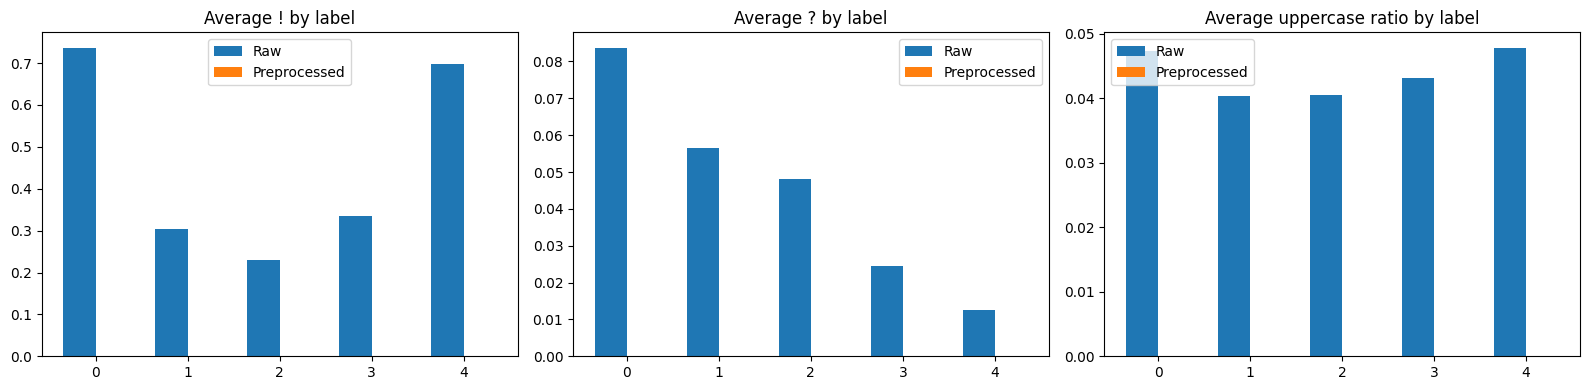

In [52]:
x = np.arange(len(punct_summary))
width = 0.35

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].bar(x - width/2, punct_summary["raw_avg_exclamation"], width=width, label="Raw")
axes[0].bar(x + width/2, punct_summary["prep_avg_exclamation"], width=width, label="Preprocessed")
axes[0].set_title("Average ! by label")
axes[0].set_xticks(x)
axes[0].set_xticklabels(punct_summary[LABEL_COL].astype(str))
axes[0].legend()

axes[1].bar(x - width/2, punct_summary["raw_avg_question"], width=width, label="Raw")
axes[1].bar(x + width/2, punct_summary["prep_avg_question"], width=width, label="Preprocessed")
axes[1].set_title("Average ? by label")
axes[1].set_xticks(x)
axes[1].set_xticklabels(punct_summary[LABEL_COL].astype(str))
axes[1].legend()

axes[2].bar(x - width/2, punct_summary["raw_avg_uppercase_ratio"], width=width, label="Raw")
axes[2].bar(x + width/2, punct_summary["prep_avg_uppercase_ratio"], width=width, label="Preprocessed")
axes[2].set_title("Average uppercase ratio by label")
axes[2].set_xticks(x)
axes[2].set_xticklabels(punct_summary[LABEL_COL].astype(str))
axes[2].legend()

plt.tight_layout()
plt.show()

In [53]:
print_section("FINAL SUMMARY TABLE")

# ----------------------------
# 1. Negation summary by label
# ----------------------------
negation_final = negation_summary.copy()

negation_final["negation_delta_pct_points"] = (
    negation_final["pct_docs_with_negation_preprocessed"]
    - negation_final["pct_docs_with_negation_raw"]
)

negation_final = negation_final[[
    LABEL_COL,
    "n_docs",
    "pct_docs_with_negation_raw",
    "pct_docs_with_negation_preprocessed",
    "avg_negation_count_raw",
    "avg_negation_count_preprocessed",
    "negation_delta_pct_points",
]].copy()

negation_final["section"] = "negation_by_label"


# ----------------------------------------
# 2. Top negation words across all reviews
# ----------------------------------------
top_neg_words_final = neg_word_stats.head(10).copy()
top_neg_words_final["section"] = "top_negation_words"

top_neg_words_final = top_neg_words_final[[
    "section",
    "negation_word",
    "doc_count",
    "doc_pct",
    "occ_count",
    "occ_per_doc_pct",
]].copy()


# ---------------------------------------
# 3. Punctuation summary by label
# ---------------------------------------
punct_final = punct_summary.copy()

punct_final["exclamation_delta"] = (
    punct_final["prep_avg_exclamation"] - punct_final["raw_avg_exclamation"]
)
punct_final["question_delta"] = (
    punct_final["prep_avg_question"] - punct_final["raw_avg_question"]
)
punct_final["uppercase_delta"] = (
    punct_final["prep_avg_uppercase_ratio"] - punct_final["raw_avg_uppercase_ratio"]
)

punct_final = punct_final[[
    LABEL_COL,
    "n_docs",
    "raw_avg_exclamation",
    "prep_avg_exclamation",
    "exclamation_delta",
    "raw_avg_question",
    "prep_avg_question",
    "question_delta",
    "raw_avg_repeated_exclamation",
    "prep_avg_repeated_exclamation",
    "raw_avg_repeated_question",
    "prep_avg_repeated_question",
    "raw_avg_mixed_punct_runs",
    "prep_avg_mixed_punct_runs",
    "raw_avg_uppercase_ratio",
    "prep_avg_uppercase_ratio",
    "uppercase_delta",
]].copy()

punct_final["section"] = "punctuation_by_label"


# -----------------------------------------------------
# 4. Extra compact ranking tables for easier reading
# -----------------------------------------------------
negation_rank = negation_summary[[LABEL_COL, "pct_docs_with_negation_preprocessed"]].copy()
negation_rank = negation_rank.sort_values("pct_docs_with_negation_preprocessed", ascending=False)
negation_rank["rank"] = range(1, len(negation_rank) + 1)
negation_rank["section"] = "negation_rank_preprocessed"
negation_rank = negation_rank[["section", "rank", LABEL_COL, "pct_docs_with_negation_preprocessed"]]

punct_excl_rank = punct_summary[[LABEL_COL, "raw_avg_exclamation"]].copy()
punct_excl_rank = punct_excl_rank.sort_values("raw_avg_exclamation", ascending=False)
punct_excl_rank["rank"] = range(1, len(punct_excl_rank) + 1)
punct_excl_rank["section"] = "raw_exclamation_rank"
punct_excl_rank = punct_excl_rank[["section", "rank", LABEL_COL, "raw_avg_exclamation"]]

punct_upper_rank = punct_summary[[LABEL_COL, "raw_avg_uppercase_ratio"]].copy()
punct_upper_rank = punct_upper_rank.sort_values("raw_avg_uppercase_ratio", ascending=False)
punct_upper_rank["rank"] = range(1, len(punct_upper_rank) + 1)
punct_upper_rank["section"] = "raw_uppercase_rank"
punct_upper_rank = punct_upper_rank[["section", "rank", LABEL_COL, "raw_avg_uppercase_ratio"]]


# -----------------------------------------------------
# 5. Dataset-level high-level summary (single-row table)
# -----------------------------------------------------
dataset_overview = pd.DataFrame([{
    "section": "dataset_overview",
    "n_docs_total": len(train_df),
    "top_negation_word": neg_word_stats.iloc[0]["negation_word"] if len(neg_word_stats) > 0 else None,
    "top_negation_word_doc_pct": neg_word_stats.iloc[0]["doc_pct"] if len(neg_word_stats) > 0 else None,
    "second_negation_word": neg_word_stats.iloc[1]["negation_word"] if len(neg_word_stats) > 1 else None,
    "second_negation_word_doc_pct": neg_word_stats.iloc[1]["doc_pct"] if len(neg_word_stats) > 1 else None,
    "label_with_highest_negation_preprocessed": negation_summary.sort_values(
        "pct_docs_with_negation_preprocessed", ascending=False
    ).iloc[0][LABEL_COL],
    "highest_negation_preprocessed_pct": negation_summary["pct_docs_with_negation_preprocessed"].max(),
    "label_with_highest_raw_exclamation": punct_summary.sort_values(
        "raw_avg_exclamation", ascending=False
    ).iloc[0][LABEL_COL],
    "highest_raw_exclamation": punct_summary["raw_avg_exclamation"].max(),
    "label_with_highest_raw_uppercase_ratio": punct_summary.sort_values(
        "raw_avg_uppercase_ratio", ascending=False
    ).iloc[0][LABEL_COL],
    "highest_raw_uppercase_ratio": punct_summary["raw_avg_uppercase_ratio"].max(),
}])


# -----------------------------------------------------
# 6. Display all summary tables cleanly
# -----------------------------------------------------
print("\n--- DATASET OVERVIEW ---")
display(dataset_overview)

print("\n--- NEGATION SUMMARY BY LABEL ---")
display(negation_final.sort_values(LABEL_COL))

print("\n--- TOP NEGATION WORDS ---")
display(top_neg_words_final)

print("\n--- NEGATION RANK (PREPROCESSED) ---")
display(negation_rank)

print("\n--- PUNCTUATION SUMMARY BY LABEL ---")
display(punct_final.sort_values(LABEL_COL))

print("\n--- RAW EXCLAMATION RANK ---")
display(punct_excl_rank)

print("\n--- RAW UPPERCASE RANK ---")
display(punct_upper_rank)


FINAL SUMMARY TABLE

--- DATASET OVERVIEW ---


,section,n_docs_total,top_negation_word,top_negation_word_doc_pct,second_negation_word,second_negation_word_doc_pct,label_with_highest_negation_preprocessed,highest_negation_preprocessed_pct,label_with_highest_raw_exclamation,highest_raw_exclamation,label_with_highest_raw_uppercase_ratio,highest_raw_uppercase_ratio
0,dataset_overview,252000,nicht,24.302381,not,17.309524,0.0,77.718254,0.0,0.736607,4.0,0.047813



--- NEGATION SUMMARY BY LABEL ---


,label,n_docs,pct_docs_with_negation_raw,pct_docs_with_negation_preprocessed,avg_negation_count_raw,avg_negation_count_preprocessed,negation_delta_pct_points,section
0,0,50400,74.890873,77.718254,1.570278,1.658472,2.827381,negation_by_label
1,1,50400,70.015873,72.777778,1.405516,1.484266,2.761905,negation_by_label
2,2,50400,61.005952,63.492063,1.133175,1.197262,2.486111,negation_by_label
3,3,50400,42.267857,44.222222,0.705437,0.745615,1.954365,negation_by_label
4,4,50400,28.051587,29.537698,0.422242,0.446845,1.486111,negation_by_label



--- TOP NEGATION WORDS ---


...

,label,n_docs,raw_avg_exclamation,prep_avg_exclamation,exclamation_delta,raw_avg_question,prep_avg_question,question_delta,raw_avg_repeated_exclamation,prep_avg_repeated_exclamation,raw_avg_repeated_question,prep_avg_repeated_question,raw_avg_mixed_punct_runs,prep_avg_mixed_punct_runs,raw_avg_uppercase_ratio,prep_avg_uppercase_ratio,uppercase_delta,section
0,0,50400,0.736607,0.0,-0.736607,0.083710,0.0,-0.083710,0.124008,0.0,0.010456,0.0,0.138512,0.0,0.047255,0.0,-0.047255,punctuation_by_label
1,1,50400,0.303056,0.0,-0.303056,0.056508,0.0,-0.056508,0.039544,0.0,0.005675,0.0,0.048254,0.0,0.040367,0.0,-0.040367,punctuation_by_label
2,2,50400,0.229067,0.0,-0.229067,0.048214,0.0,-0.048214,0.026091,0.0,0.004226,0.0,0.033016,0.0,0.040569,0.0,-0.040569,punctuation_by_label
3,3,50400,0.333889,0.0,-0.333889,0.024405,0.0,-0.024405,0.028274,0.0,0.001667,0.0,0.031210,0.0,0.043067,0.0,-0.043067,punctuation_by_label
4,4,50400,0.698631,0.0,-0.698631,0.012560,0.0,-0.012560,0.080377,0.0,0.000655,0.0,0.081667,0.0,0.047813,0.0,-0.047813,punctuation_by_label



--- RAW EXCLAMATION RANK ---


,section,rank,label,raw_avg_exclamation
0,raw_exclamation_rank,1,0,0.736607
4,raw_exclamation_rank,2,4,0.698631
3,raw_exclamation_rank,3,3,0.333889
1,raw_exclamation_rank,4,1,0.303056
2,raw_exclamation_rank,5,2,0.229067



--- RAW UPPERCASE RANK ---


,section,rank,label,raw_avg_uppercase_ratio
4,raw_uppercase_rank,1,4,0.047813
0,raw_uppercase_rank,2,0,0.047255
3,raw_uppercase_rank,3,3,0.043067
2,raw_uppercase_rank,4,2,0.040569
1,raw_uppercase_rank,5,1,0.040367
